# Review 1 – Classification Part A
## Heart Disease Prediction using Machine Learning

**Dataset:** Heart Failure Prediction Dataset  
**Target:** `HeartDisease`

### Problem Statement
To predict whether a patient has heart disease using demographic, clinical and exercise-related attributes.

### Review 1 Coverage
This notebook covers EDA, data cleaning, preprocessing, feature engineering and the five required Classification Part-A algorithms.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

pd.set_option('display.max_columns', None)


In [2]:
df = pd.read_csv("../data/heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
print(df["HeartDisease"].value_counts())
print("\nTarget percentage:")
print(df["HeartDisease"].value_counts(normalize=True) * 100)
print("\nSummary:")
print(df.describe())

Shape: (918, 12)

Columns:
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

Data types:
Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Duplicate rows: 0

Target distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64

Target percentage:
HeartDisease
1    55.337691
0    44.662309
Name: p

### Dataset Audit Observation
The target `HeartDisease` has two classes, 0 and 1, making this a binary classification problem. Missing values and duplicate rows are checked before modelling.

In [4]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (918, 12)


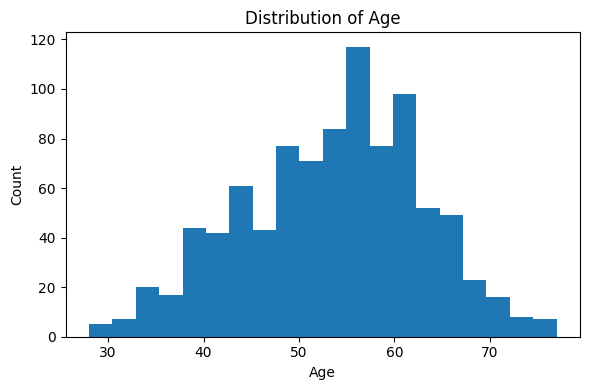

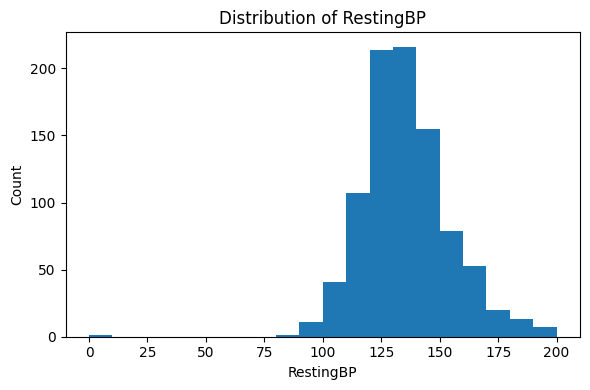

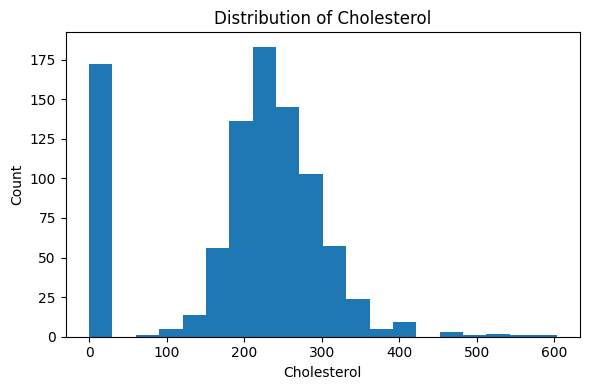

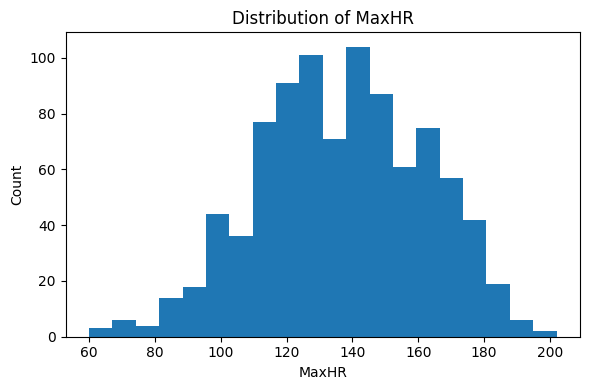

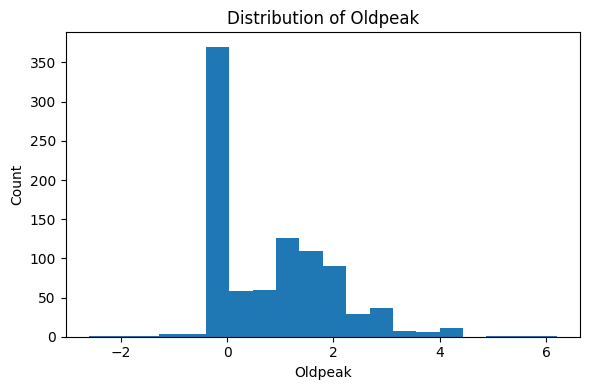

In [5]:
numeric_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

for col in numeric_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=20)
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

### Numerical Distribution Observation
The numerical features have different ranges. Age and maximum heart rate show useful variation among patients, while cholesterol, resting blood pressure and Oldpeak also contain a wide range of values.

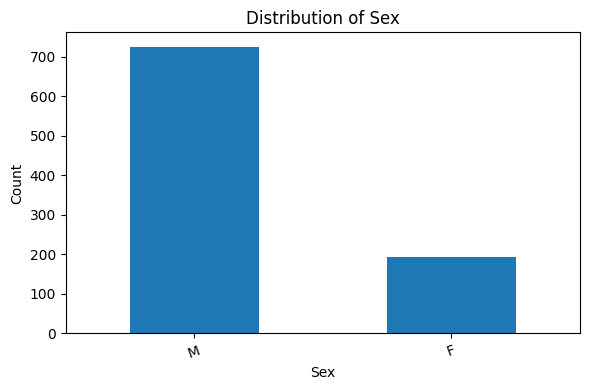

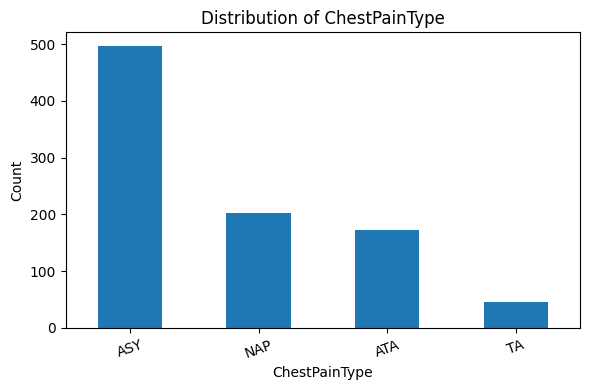

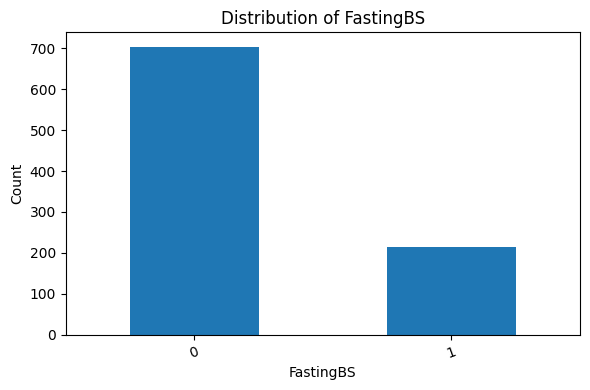

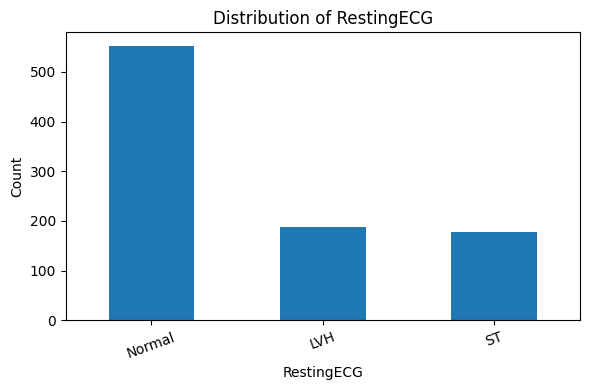

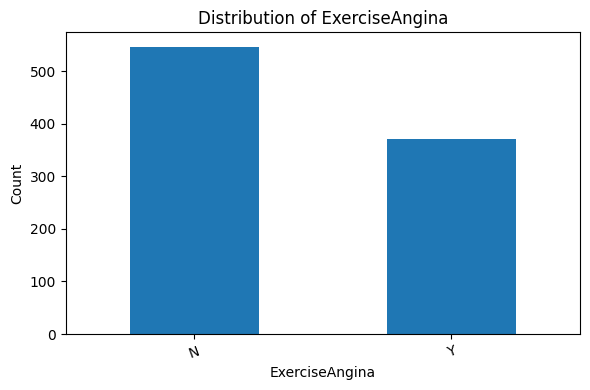

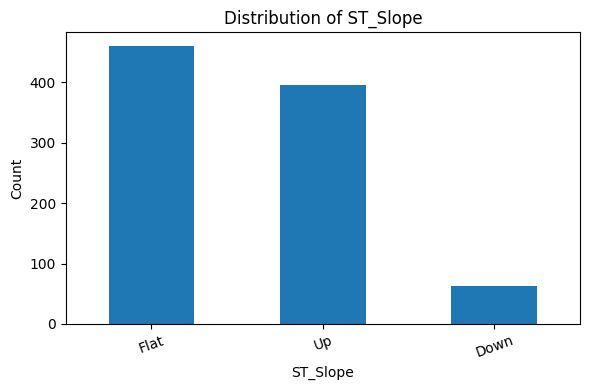

In [6]:
categorical_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]

for col in categorical_cols:
    plt.figure(figsize=(6,4))
    df[col].value_counts().plot(kind="bar")
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

### Categorical Distribution Observation
The categorical variables show differences in the number of patients in each category. Chest pain type, exercise angina and ST slope are especially useful features to investigate because they are related to cardiac condition.

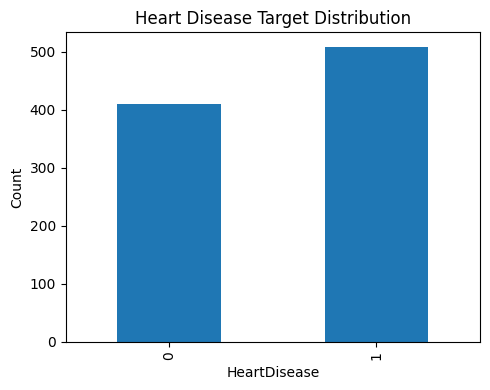

In [7]:
plt.figure(figsize=(5,4))
df["HeartDisease"].value_counts().sort_index().plot(kind="bar")
plt.title("Heart Disease Target Distribution")
plt.xlabel("HeartDisease")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Target Observation
Both target classes are represented in the dataset. The distribution is reasonably balanced, so stratified splitting can be used to maintain similar class proportions in the training and testing sets.

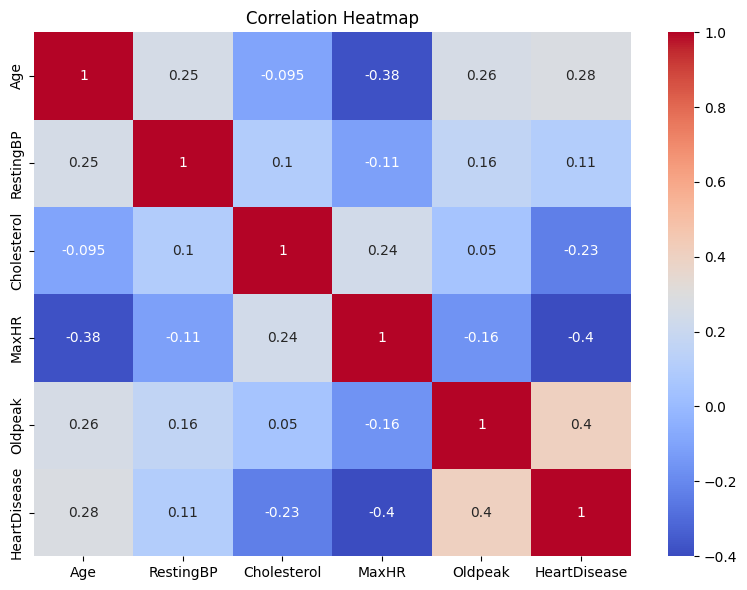

In [8]:
corr_cols = numeric_cols + ["HeartDisease"]
plt.figure(figsize=(8,6))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Correlation Observation
The heatmap shows the numerical relationships with heart disease. Some variables have stronger relationships with the target than others, which helps us understand which features may be useful for classification.

<Figure size 600x400 with 0 Axes>

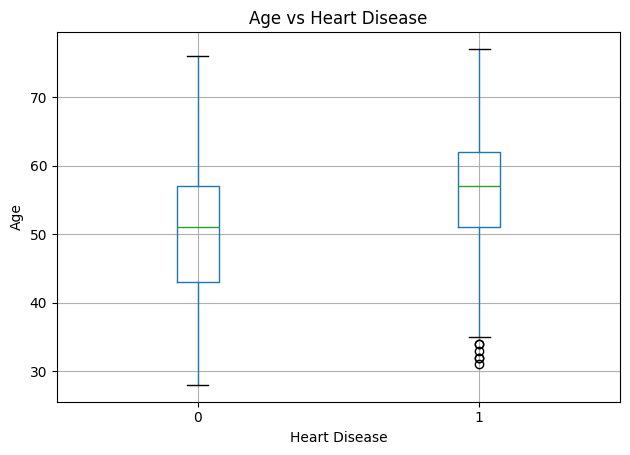

<Figure size 600x400 with 0 Axes>

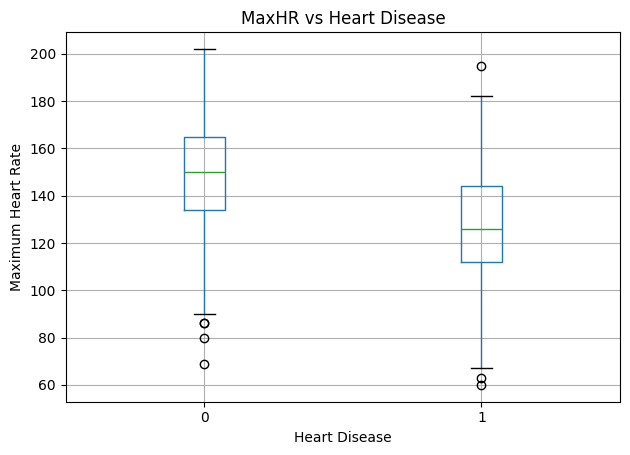

In [9]:
plt.figure(figsize=(6,4))
df.boxplot(column="Age", by="HeartDisease")
plt.title("Age vs Heart Disease")
plt.suptitle("")
plt.xlabel("Heart Disease")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
df.boxplot(column="MaxHR", by="HeartDisease")
plt.title("MaxHR vs Heart Disease")
plt.suptitle("")
plt.xlabel("Heart Disease")
plt.ylabel("Maximum Heart Rate")
plt.tight_layout()
plt.show()

### Feature-Target Observation
The boxplots show differences in age and maximum heart rate between the two heart-disease classes. These differences indicate that the features can contribute to classification.

In [10]:
# Simple IQR outlier check for numerical features
outlier_table = []
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_table.append([col, lower, upper, count])

pd.DataFrame(outlier_table, columns=["Feature","Lower Limit","Upper Limit","Outliers"])

,Feature,Lower Limit,Upper Limit,Outliers
0,Age,27.500,79.500,0
1,RestingBP,90.000,170.000,28
2,Cholesterol,32.625,407.625,183
3,MaxHR,66.000,210.000,2
4,Oldpeak,-2.250,3.750,16


### Outlier Treatment
Numerical outliers are checked using the IQR method. Extreme values are capped rather than deleting patients, because unusual clinical measurements may still contain useful information.

In [11]:
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df[col] = df[col].clip(lower, upper)

# Feature engineering
df["Age_MaxHR"] = df["Age"] * df["MaxHR"]
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Age_MaxHR
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0,6880
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1,7644
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0,3626
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1,5184
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0,6588


### Feature Engineering Observation
The `Age_MaxHR` feature combines age and maximum heart rate. This interaction may help the classifiers identify patterns that are not visible when the two variables are considered separately.

In [12]:
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

X = pd.get_dummies(
    X,
    columns=["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"],
    drop_first=True
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (734, 16)
Testing data: (184, 16)


### Preprocessing Observation
Categorical variables are converted to dummy variables. The data is split using stratification so both classes remain represented in similar proportions. StandardScaler is fitted only on the training data.

# Classification Part A Models

The five required Review 1 algorithms are Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree and SVC.

In [13]:
classification_results = []

### Logistic Regression

In [14]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:,1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted")
auc = roc_auc_score(y_test, y_prob)

classification_results.append(["Logistic Regression", accuracy, precision, recall, f1, auc])

print("Accuracy:", accuracy)
print("Weighted F1:", f1)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8858695652173914
Weighted F1: 0.8852184150325296
Confusion Matrix:
[[68 14]
 [ 7 95]]


### KNN

In [15]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:,1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted")
auc = roc_auc_score(y_test, y_prob)

classification_results.append(["KNN", accuracy, precision, recall, f1, auc])

print("Accuracy:", accuracy)
print("Weighted F1:", f1)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8858695652173914
Weighted F1: 0.8859343055744854
Confusion Matrix:
[[72 10]
 [11 91]]


### Gaussian Naive Bayes

In [16]:
model = GaussianNB()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:,1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted")
auc = roc_auc_score(y_test, y_prob)

classification_results.append(["Gaussian Naive Bayes", accuracy, precision, recall, f1, auc])

print("Accuracy:", accuracy)
print("Weighted F1:", f1)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.907608695652174
Weighted F1: 0.9075506313878823
Confusion Matrix:
[[73  9]
 [ 8 94]]


### Decision Tree Classifier

In [17]:
model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted")
auc = roc_auc_score(y_test, y_prob)

classification_results.append(["Decision Tree Classifier", accuracy, precision, recall, f1, auc])

print("Accuracy:", accuracy)
print("Weighted F1:", f1)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8097826086956522
Weighted F1: 0.8093887838689351
Confusion Matrix:
[[63 19]
 [16 86]]


### Support Vector Machine (SVC)

In [18]:
model = SVC(C=1.0, kernel='rbf', probability=True)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:,1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted")
auc = roc_auc_score(y_test, y_prob)

classification_results.append(["Support Vector Machine (SVC)", accuracy, precision, recall, f1, auc])

print("Accuracy:", accuracy)
print("Weighted F1:", f1)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.907608695652174
Weighted F1: 0.9068782964265255
Confusion Matrix:
[[69 13]
 [ 4 98]]


### Model Observation
Accuracy and weighted F1 show the overall classification performance. The confusion matrix shows how many patients were correctly and incorrectly classified in each class.

## Preliminary Classification Comparison

In [19]:
classification_df = pd.DataFrame(
    classification_results,
    columns=["Model","Accuracy","Precision","Recall","Weighted F1","ROC-AUC"]
)

classification_df.sort_values("Weighted F1", ascending=False).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Gaussian Naive Bayes,0.907609,0.912621,0.921569,0.907551,0.943209
1,Support Vector Machine (SVC),0.907609,0.882883,0.960784,0.906878,0.943089
2,KNN,0.885870,0.900990,0.892157,0.885934,0.939204
3,Logistic Regression,0.885870,0.871560,0.931373,0.885218,0.930297
4,Decision Tree Classifier,0.809783,0.819048,0.843137,0.809389,0.821019


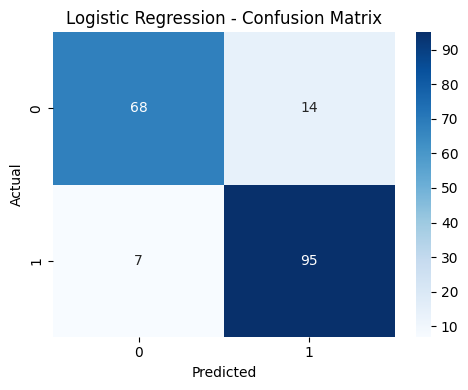

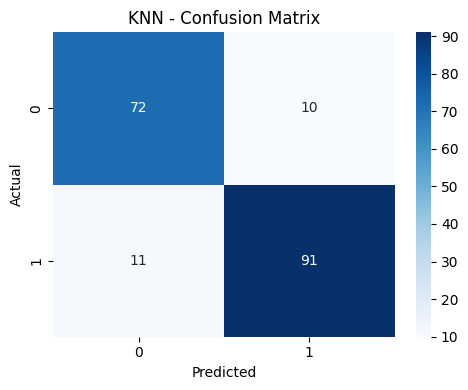

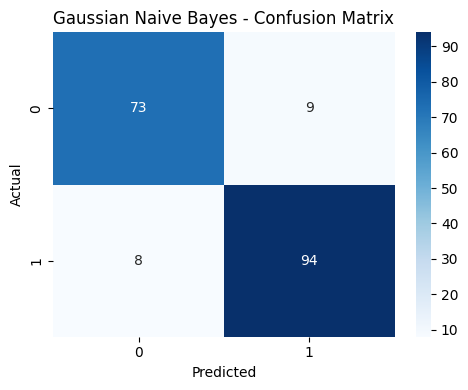

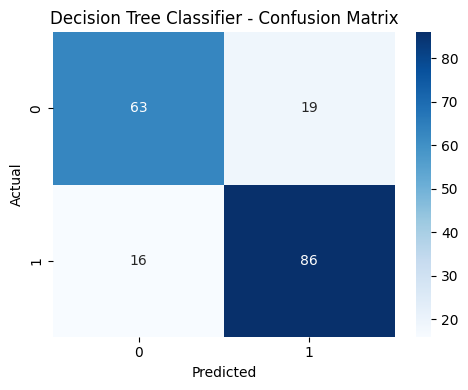

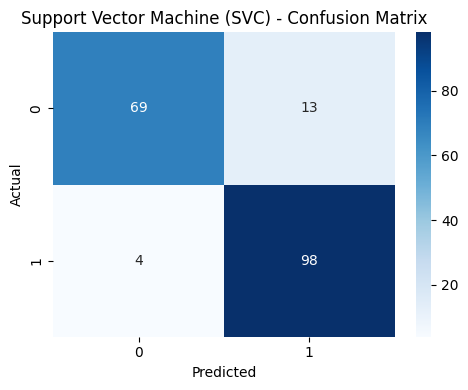

In [20]:
# Confusion matrices for all five algorithms
for row in classification_results:
    name = row[0]
    if name == "Logistic Regression":
        model = LogisticRegression(max_iter=1000)
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
    elif name == "KNN":
        model = KNeighborsClassifier(n_neighbors=5)
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
    elif name == "Gaussian Naive Bayes":
        model = GaussianNB()
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
    elif name == "Decision Tree Classifier":
        model = DecisionTreeClassifier(max_depth=5, random_state=42)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
    else:
        model = SVC(C=1.0, kernel="rbf")
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)

    plt.figure(figsize=(5,4))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues")
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

## Review 1 Classification Conclusion
Five required Part-A classification algorithms were trained on the same classification dataset and evaluated using Accuracy, weighted F1-score and confusion matrices. The comparison table is used to identify the preliminary best model. Part B algorithms belong to Review 2 and are not included here.